# Benchmark eye state dan KSS

Metrik diambil dari saved run artifacts. Model disimpan/reload; split dipisahkan berdasarkan subjek.

In [1]:
from pathlib import Path
import os
for key in ('OMP_NUM_THREADS', 'OPENBLAS_NUM_THREADS', 'MKL_NUM_THREADS', 'NUMBA_NUM_THREADS'):
    os.environ.setdefault(key, '4')
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').exists())
os.chdir(ROOT)
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from atc_fatigue.utils.runtime import load_config
config = load_config()
%matplotlib inline


In [2]:
mrl = json.loads(Path('reports/metrics/mrl_eye_seed42_v1/metrics.json').read_text())
display(pd.DataFrame({name: {k: scores['test'][k] for k in ['macro_f1', 'balanced_accuracy', 'accuracy']} for name, scores in mrl['models'].items()}).T)
splits = pd.read_csv('reports/metrics/mrl_eye_seed42_v1/split_manifest.csv')
assert splits.groupby('subject_id').split.nunique().max() == 1
display(splits.groupby('split').agg(images=('sample_id', 'size'), subjects=('subject_id', 'nunique')))

,macro_f1,balanced_accuracy,accuracy
dummy_majority,0.355753,0.500000,0.552200
hog_linear_svm,0.787665,0.787206,0.790336


,images,subjects
split,,
test,1159,8
train,3234,23
validation,892,6


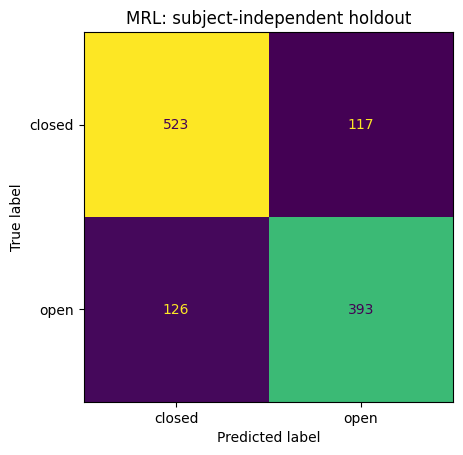

In [3]:
from sklearn.metrics import ConfusionMatrixDisplay
result = mrl['models']['hog_linear_svm']['test']
ConfusionMatrixDisplay(np.array(result['confusion_matrix']), display_labels=['closed', 'open']).plot(colorbar=False)
plt.title('MRL: subject-independent holdout'); plt.show()

In [4]:
from atc_fatigue.models.baselines import predict_artifact
features = pd.read_parquet('data/interim/mrl_hog_features.parquet')
holdout = splits[splits.split.eq('test')].merge(features, on='sample_id')
pred = predict_artifact('models/mrl_eye_seed42_v1/hog_linear_svm.joblib', holdout)
recorded = pd.read_csv('reports/metrics/mrl_eye_seed42_v1/predictions.csv')
recorded = recorded[(recorded.model == 'hog_linear_svm') & (recorded.split == 'test')]
check = pd.DataFrame({'sample_id': holdout.sample_id, 'reload_prediction': pred}).merge(recorded[['sample_id', 'prediction']], on='sample_id')
assert check.reload_prediction.eq(check.prediction).all()
display(check.head())

,sample_id,reload_prediction,prediction
0,s0005_00006_0_0_0_0_0_01,0,0
1,s0005_00009_0_0_0_0_0_01,0,0
2,s0005_00015_0_0_0_0_0_01,0,0
3,s0005_00018_0_0_0_0_0_01,0,0
4,s0005_00038_0_0_0_0_0_01,0,0


In [5]:
kss = json.loads(Path('reports/metrics/drozy_kss_loso_v1/metrics.json').read_text())
print(kss['test_level_rows'], 'test-level labels;', kss['subjects'], 'subjects')
display(pd.DataFrame(kss['models']).T)
print('Target: KSS sleepiness regression, not ATC fatigue.')

36 test-level labels; 14 subjects


,mae,rmse,subject_macro_mae,reload_verified
dummy_mean,2.051866,2.270424,2.108202,True
ridge_alpha1,1.45444,1.817016,1.44051,True


Target: KSS sleepiness regression, not ATC fatigue.


Hasil subset MRL tidak mengukur prevalensi alami. KSS regression bersifat preliminary dan offline; angka error tidak membuktikan validitas fatigue atau performa real-time.